# A seasonal reference before a complex forecast

**Question:** On the committed trend-plus-seasonal case, how do a repeated season and finite-history Theta differ when they forecast the same unseen block?

## Objectives

Build a reference that a decision maker can inspect before considering a larger model. We will separate observations available at the forecast origin from observations reserved for scoring, run three actual product methods, and compare errors using one historical scale. The example is generated, rather than a record of warehouse sales. Its trend and seasonality help explain a mechanism without providing evidence about the economic performance of an inventory policy.

The key distinction is between a forecast and its evaluation denominator. SeasonalNaive is a particular prediction path. MASE scales an arbitrary method's error by historical seasonal differences. These operations use related ideas but different observations. A MASE below one does not, by itself, establish that a method beat the SeasonalNaive path on the future block. We will score both forecasts explicitly instead of drawing that unsupported conclusion.

## Setup

Create the isolated environment with the repository's notebook initialization workflow. These exact direct dependencies identify the lesson environment; the notebook never installs packages while executing.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
```

The imports below use the product implementation. No forecasting equation is copied into a notebook cell.


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "product.json").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from chronoscopelab.model.forecasters import gaussian_quantiles
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
from chronoscopelab.engines.statsforecast_engine import StatsforecastForecaster
from chronoscopelab.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Data

The committed `TRND_seasonal` trace contains the fitting prefix and the final target block as separate arrays. Both are loaded for this explanation, but only the prefix is passed into forecasting functions. The seasonal period and horizon are read from the same trace. This keeps the question tied to the actual artifact rather than substituting a conveniently chosen simulation. Inspect the printed sizes before interpreting any forecast.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Method

SeasonalNaive repeats the most recently observed cycle. If the horizon extends beyond a cycle, that cycle repeats again. It introduces no extrapolated trend, so its appeal is inspectability and low estimation variance. The cost is a predictable lag when the level keeps rising. A planner can often recognize this limitation directly: next month's value is copied from a comparable position in the past despite continued growth since then. The first computation exposes that specific prediction, not a fitted accuracy claim.


In [3]:
# Repeat the final observed season without using actual in fitting.
naive, naive_sigma = seasonal_naive(history, m, h)
naive_q = gaussian_quantiles(naive, naive_sigma, (0.1, 0.5, 0.9))
print("SeasonalNaive first prediction:", round(float(naive[0]), 4))


SeasonalNaive first prediction: 112.5375


Theta combines a locally smoothed level with a drift contribution derived from the fitted linear trend. The product uses the finite-history correction described by Hyndman and Billah. That correction matters because the smoothed trend contribution already incorporates part of the drift; simply adding another full drift would count it twice. This local implementation does not perform AutoTheta's automatic seasonal adjustment or model selection. The shared name therefore does not make these two implementations interchangeable.


In [4]:
# Fit the finite-history Theta implementation on the same prefix.
theta_point, theta_sigma = theta(history, m, h)
theta_q = gaussian_quantiles(theta_point, theta_sigma, (0.1, 0.5, 0.9))
print("Theta first prediction:", round(float(theta_point[0]), 4))


Theta first prediction: 113.1748


Holt adds a separately updated trend to the level. We include it as a deliberately incomplete explanation of this seasonal series. A plausible trend can still miss recurring peaks and troughs. Running it illustrates why a model's components should be matched to a stated mechanism, rather than selected solely because the method is more elaborate than a repeated season. We retain its first forecast as a concrete diagnostic even though the following score comparison concentrates on the two methods in our question.


In [5]:
# A trend-only forecast is a useful deliberately mismatched comparator.
holt_point, holt_sigma = holt(history, m, h)
print("Holt first prediction:", round(float(holt_point[0]), 4))


Holt first prediction: 114.6561


For each method, MAE is the mean absolute future error. MASE divides that MAE by the mean absolute seasonal difference inside the fitting prefix. The scale is computed once from information available at the origin. An unusually smooth historical cycle makes that denominator small and can produce a large MASE even when the absolute errors look modest. Conversely, a noisy history can lower scaled error without changing a forecast's operational usefulness. Units and the historical scale must accompany interpretation.


In [6]:
# Score the same future block with one historical seasonal scale.
scores_naive = metrics(history, actual, naive, naive_q[:, 0], naive_q[:, 2], m)
scores_theta = metrics(history, actual, theta_point, theta_q[:, 0], theta_q[:, 2], m)
print("SeasonalNaive MASE:", round(scores_naive["mase"], 4))
print("Theta MASE:", round(scores_theta["mase"], 4))


SeasonalNaive MASE: 0.6464
Theta MASE: 1.4225


The plot places the final historical observations and both forecasts on the same axes. The dashed origin separates information available for fitting from information revealed later for scoring. Look for three features: continuation of the level, alignment of seasonal peaks, and increasing separation across the horizon. The vertical scale is shared, so visual differences correspond to actual value differences rather than independently normalized panels. No smoothing is applied to the held-out observations.


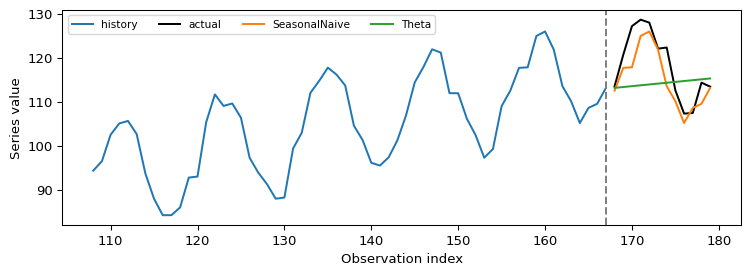

In [7]:
# Plot the observed cut and both competing paths on a shared vertical scale.
fig, ax = plt.subplots()
x = np.arange(len(history), len(history) + h)
ax.plot(np.arange(len(history))[-60:], history[-60:], label="history")
ax.plot(x, actual, label="actual", color="black")
ax.plot(x, naive, label="SeasonalNaive")
ax.plot(x, theta_point, label="Theta")
ax.axvline(len(history) - 1, color="grey", linestyle="--")
ax.set(xlabel="Observation index", ylabel="Series value")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()


The figure shows why a forecast can follow the recent seasonal shape yet miss the new level. Theta instead projects a drift while expressing less of the detailed cycle. Neither visible pattern establishes a universal ranking. Their relative errors depend on the series, the forecast origin and the length of the reserved block. The printed MASE values above answer this particular experiment more precisely than judging which line looks smoother.

## Results

**Answer:** The methods forecast the same 12 held-out observations, but use different assumptions about repeated seasonality and continued drift. Compare their printed MASE values to decide which had lower error in this case. The number of future observations is a scope statement, not a sample size supporting a population claim. A separate SeasonalNaive score is necessary to establish a direct improvement over that reference.

The Gaussian quantiles used for these light methods derive from fitted residual scale and a widening rule. They have not acquired conditional coverage merely because their columns are ordered. Before a stocking decision, compare interval misses, widths and asymmetric shortage costs over repeated operational origins. A single generated block is useful for understanding a mechanism and catching an implementation defect, but is inadequate evidence for an operational service-level guarantee.

## Summary

Start with a visible temporal cut, preserve the exact target, and fit every competitor on the same prefix. Distinguish a historical error scale from a future baseline prediction. The next lesson deliberately moves the origin into an unfinished season, where incorrect indexing can change which seasonal component a method forecasts. That is an implementation question we can answer with a focused experiment before increasing model size or training cost.

## References

- Forecast scaling: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Finite-history Theta equation: https://robjhyndman.com/papers/Theta.pdf
- Seasonal continuation: https://otexts.com/fpp3/holt-winters.html
- Feature-dependent combinations, for the later lessons: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Dynamic ensembles, for the later lessons: https://doi.org/10.1007/s10994-018-05774-y
